# Results visualisation and graphs generation
- [X] Fairness Level: how fairness metrics change w.r.t. the level of fairness (hyperparams);
- [ ] Fairness metrics of Mitigated;
- [ ] Accuracy metrics of Discriminator;

In [ ]:
from PIL.ImageColor import colormap


def fairness_level_plot_old(dataset_results, dataset, mode="bar"):
    rename_cols = {
        "debiasing_lv": "Debiasing level",
        "debiasing_type": "Debiasing model",
    }

    if mode == "bar":
        g = sns.catplot(
            data=dataset_results.rename(columns=rename_cols),
            kind="bar",
            x="Debiasing model",
            y="debiasing_DP-diff",
            hue="Debiasing level",
            col="dataset",
            row="sensitive",
            height=4,
            aspect=2
        )
        g.set_axis_labels("Debiasing Methods", "DP Diff")
        g.set_titles("{col_name} | {row_name}")
    elif mode == "point":
        g = sns.catplot(
            data=dataset_results.rename(columns=rename_cols),
            kind="point",
            x="Debiasing level",
            y="debiasing_DP-diff",
            hue="Debiasing model",
            col="dataset",
            row="sensitive",
            dodge=True,
            markers="o",
            linestyles="-",
            height=4,
            aspect=2
        )
        g.set_axis_labels("Debiasing Methods", "DP Diff")
        g.set_titles("{col_name} | {row_name}")
    g._legend.remove()

    handles, labels = g.axes[0, 0].get_legend_handles_labels()
    fig_leg = plt.figure(figsize=(6, 1))
    fig_leg.legend(handles, labels, loc="center", ncol=3, frameon=False)


    #save_plot(fig_leg, "../out/figures/{}_fairness_levels_{}_legend".format(dataset, mode))
    #save_plot(g, "../out/figures/{}_fairness_levels_{}".format(dataset, mode))
    plt.close(fig_leg)



In [ ]:
import pickle
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
from itertools import product

results_path = "../out/results_{}.df"
checkpoints_path = "../out/checkpoints_{}.df"

datasets = ['adult', 'bank_marketing', 'credit_card']
metrics_to_explode = ['accuracy', 'fairness']
cols_to_explode_prefx = ["unm_model", "debiasing", "discr_model"]

#datasets = ['bank_marketing']

results = []
for d in datasets:
    print(d)
    with open(results_path.format(d), 'rb') as f:
        df = pickle.load(f)
        # pre-process
        df = extract_metrics(df, metrics_to_explode, cols_to_explode_prefx)
        #fairness_level_plot(df, d, mode="point")
        fairness_level_plot_old(df, d, mode="bar")
        results.append(df)


In [ ]:
df

In [ ]:
cols_to_view = ['sensitive', 'debiasing_lv', 'debiasing_type', 'debiasing_f1_score', 'debiasing_DP-diff', 'debiasing_DP-ratio']

results[0][cols_to_view].drop_duplicates()


In [ ]:
df_plot = pd.concat([
    results[0][[
        "dataset",
        "sensitive",
        "unm_model_f1_score",
        "unm_model_DP-ratio"
    ]].rename(columns={
        "unm_model_f1_score": "f1_score",
        "unm_model_DP-ratio": "dp_ratio"
    }).assign(method="unmitigated"),

    results[0][[
        "dataset",
        "sensitive",
        "debiasing_accuracy_score",
        "debiasing_DP-ratio",
        "debiasing_type",
        "debiasing_lv"
    ]].rename(columns={
        "debiasing_f1_score": "f1_score",
        "debiasing_DP-ratio": "dp_ratio"
    }).assign(method=lambda x: x["debiasing_type"])
])
df_plot = df_plot.drop_duplicates()

In [ ]:
df_plot

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

g = sns.catplot(
    data=df_plot,
    kind="point",
    x="debiasing_lv",
    y="dp_ratio",
    hue="method",
    col="dataset",
    row="sensitive",
    dodge=True,
    markers="o",
    linestyles="-",
    height=4,
    aspect=1.2
)

g.set_axis_labels("Debiasing Level", "DP Ratio")
g.set_titles("{col_name} | {row_name}")

for ax in g.axes.flat:
    ax.axhline(1.0, linestyle="--", color="gray")

plt.show()

In [ ]:
df_plot.drop_duplicates()

In [ ]:
results[1]

In [ ]:
with open("../out/checkpoints_bank_marketing.df", "rb") as f:
    df = pickle.load(f)
df

In [ ]:
cols_to_show = ["debiasing_type", "debiasing_lv", "discr_model_f1_score", "discr_model_type"] #+ [col for col in results[0].columns if col.startswith("discr_model")]



In [ ]:
results[0][cols_to_show]

In [ ]:
# Accuracy Classificatore
# y: accuracy metrics
# X: modelli discriminatore - modelli debiasing
# hue:

In [ ]:
results[0][results[0]['debiasing_type'] == "ThresholdOptimizer"][['debiasing_lv', 'debiasing_DP-diff']].drop_duplicates()

In [ ]:
def plot_accuracy_of_model(df):


In [ ]:
results[0]

In [ ]:

accuracy_metrics = ["f1_score", "accuracy_score"]

model_metrics = ["debiasing_" + metric for metric in accuracy_metrics]

df_metrics = results[0][model_metrics + ["debiasing_type", "debiasing_lv", "sensitive", "dataset"]].drop_duplicates()
df_metrics["model"] = df["debiasing_type"] + "_" + df["debiasing_lv"]
df_metrics

In [ ]:
df_long = results[0].melt(
    id_vars=["discr_model_type", "dataset", "sensitive"],
    value_vars=[
        "discr_model_accuracy_score",
        "discr_model_f1_score"
    ],
    var_name="metric",
    value_name="value"
)

df_long["panel"] = (
    df_long["discr_model_type"] + " | " +
    df_long["dataset"] + " | " +
    df_long["sensitive"]
)

import seaborn as sns

g = sns.catplot(
    data=df_long,
    kind="bar",
    x="metric",
    y="value",
    col="panel",
    col_wrap=3,
    height=4,
    aspect=1.2,
    dodge=False
)

In [ ]:
with open("../out/checkpoints_adult.df", "rb") as f:
    df = pickle.load(f)

In [ ]:
df

In [ ]:
final_path = "../out/final_results_{}.df"
with open(final_path.format("bank_marketing"), "rb") as f:
    df = pickle.load(f)
df = extract_metrics(df, metrics_to_explode, cols_to_explode_prefx)
fairness_level_plot(df, "credit_card", mode="point")

In [ ]:
df

In [ ]:
df[df['debiasing_lv'] == "high"]['debiasing_DP-ratio']

In [ ]:

df_deb = df[df['debiasing_type'] == "ThresholdOptimizer"]
df_deb = df[df['debiasing_type'] == "ExponentiatedGradient"]
df_deb = df[df['debiasing_type'] == "PrototypeRepresentationLearner"]

comparison_df = pd.DataFrame(columns=['debiasing_type', "low", "medium", "high"])


for i, deb in enumerate(["ThresholdOptimizer", "ExponentiatedGradient", "PrototypeRepresentationLearner"]):
    df_deb = df[df['debiasing_type'] == deb]
    comparison_df.loc[i+1] = {
            "debiasing_type": deb,
            "low": df_deb[(df_deb['debiasing_lv'] == "low")]['debiasing_DP-ratio'].mean(),
            "medium": df_deb[(df_deb['debiasing_lv'] == "medium")]['debiasing_DP-ratio'].mean(),
            "high": df_deb[(df_deb['debiasing_lv'] == "high")]['debiasing_DP-ratio'].mean()
        }

comparison_df

In [ ]:
# mathematical formulation of the problem
# approach
# literature review/background/etc...

In [ ]:
df

# Explainer

In [ ]:
import shap


unm_model_pool = ['lr']
debiasing_pool = ['to', 'eg', 'prl']
debiasing_prep = ['prl']
discr_model_pool = ['lr', 'xgb', 'mlp']


In [ ]:
import shap

d = "bank_marketing"
with open("../out/models/final_shap_xgb_lr-prl-high-marital-bank_marketing.model", "rb") as f:
    explainer_artifacts = pickle.load(f)

with open("../out/data/final_{}_probing.data".format(d), "rb") as f:
    X_probing, _ = pickle.load(f)

In [ ]:

shap.summary_plot(
    explainer_artifacts["shap_values"][:, :, 1],
    X_probing
)

# Viz

## Models Stats

In [3]:
def explode_metrics(d):
    return {key: d.get(key) for key in d.keys()}

def extract_metrics(df, metrics_to_explode, cols_to_explode_prefx):
    for col, metric in product(cols_to_explode_prefx, metrics_to_explode):
        column = "{}_{}".format(col, metric)
        extraction = df[column].apply(explode_metrics).apply(pd.Series).add_prefix(col+"_")
        df = pd.concat([df, extraction], axis=1)
    return df

def save_plot(plt, path, formats=None):
    if formats is None: formats = ["png", "pdf", "eps"]

    for fmt in formats:
        plt.savefig(f"{path}.{fmt}", dpi=300 if fmt == "png" else None, bbox_inches="tight")

def clean_string(string):
    string = " ".join(word.capitalize() for word in string.split("_"))
    string = " ".join(word.capitalize() for word in string.split("-"))
    return string

In [4]:
from src import config
import pickle
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use("default")
sns.set_theme(style="whitegrid", palette="deep")
from itertools import product

results_path = "../out/final/out/results_{}.df"

datasets = ['adult', 'bank_marketing', 'credit_card']
metrics_to_explode = ['accuracy', 'fairness']
cols_to_explode_prefx = ["unm_model", "debiasing", "discr_model"]
accuracy_metrics = ['accuracy_score', 'f1_score', 'precision', 'recall', 'matthew_coeff']
fairness_metrics = ['DP-diff', 'DP-ratio', 'EOpp-diff','EOpp-ratio', 'EOdds-diff', 'EOdds-ratio']

fairness_lvs = list(config.fairness_lv.keys())


In [5]:
results = []
for d in datasets:
    with open(results_path.format(d), 'rb') as f:
        df = pickle.load(f)
        # pre-process
        df = extract_metrics(df, metrics_to_explode, cols_to_explode_prefx)
        results.append(df)

In [ ]:
def discriminator_accuracy(results):

    mapping = {
        "LogisticRegression": "LR",
        "XGBClassifier": "XGB",
        "MLPClassifier": "MLP"
    }
    model = "discr_model"

    for results_dataset in results:
        print(results_dataset['dataset'].unique()[0])
        d = results_dataset['dataset'].unique()[0]

        for s in results_dataset['sensitive'].unique():
            print("\t", s)

            for lv in fairness_lvs:
                print("\t\t", lv)
                df = results_dataset[(results_dataset["sensitive"] == s) &
                    (results_dataset["debiasing_lv"] == lv)]

                for metric in accuracy_metrics:
                    print("\t\t\t", metric)
                    g = sns.catplot(
                        data=df,
                        kind="bar",
                        x=f"{model}_type",
                        y=f"{model}_{metric}",
                        hue= "debiasing_type",
                        height=3,
                        aspect=1
                    )
                    g.set_axis_labels("", f"{clean_string(metric)}")
                    g.fig.suptitle(f"{d} | {s} | Deb. Lv. = {lv}")
                    g.fig.tight_layout()
                    g.fig.subplots_adjust(top=0.88)
                    g.set(ylim=(-1, 1)) if metric == "matthew_coeff" else g.set(ylim=(0, 1))



                    for ax in g.axes.flat:
                        ticks = ax.get_xticks()

                        old_labels = [t.get_text() for t in ax.get_xticklabels()]
                        new_labels = [mapping.get(x, x) for x in old_labels]

                        ax.set_xticks(ticks)
                        ax.set_xticklabels(new_labels)
                        ax.set_xlabel(ax.get_xlabel(), fontsize=16, fontweight="bold")
                        ax.set_ylabel(ax.get_ylabel(), fontsize=16, fontweight="bold")
                        for label in ax.get_xticklabels():
                            label.set_fontweight("bold")
                            label.set_fontsize(16)
                        ax.set_axisbelow(True)
                        ax.grid(True, axis="y", linestyle="--", alpha=0.3)

                    g._legend.remove()

                    handles, labels = g.axes[0, 0].get_legend_handles_labels()
                    fig_leg = plt.figure(figsize=(6, 1))
                    fig_leg.legend(handles, labels, loc="center", ncol=3, frameon=False)
                    save_plot(fig_leg, "../out/figures/legends/discriminator_metrics_legend")
                    save_plot(g, f"../out/figures/plots/discriminator_{d}_{s}_{lv}_{metric}")
                    plt.close(g.fig)
                    plt.close(fig_leg)
                    #break
            #break
        #break
discriminator_accuracy(results)

In [ ]:
palette_deb_lv = {
    "low": "#C9A227",     # senape elegante (non giallo acceso)
    "medium": "#4C9F8F",  # teal morbido, molto equilibrato
    "high": "#2F5D7C"     # blu petrolio scuro e sofisticato
}

def debiasing_metrics(results):
    mapping = {
        "ThresholdOptimizer": "ThresholdOptim",
        "ExponentiatedGradient": "ExpGradient",
        "PrototypeRepresentationLearner": "PrototypeRepr",
    }
    for results_dataset in results:
        print(results_dataset['dataset'].unique()[0])
        d = results_dataset['dataset'].unique()[0]

        for s in results_dataset['sensitive'].unique():
            print("\t", s)
            df = results_dataset[(results_dataset["sensitive"] == s)]

            for metric in fairness_metrics + accuracy_metrics:
                print("\t\t", metric)
                g = sns.catplot(
                    data=df,
                    kind="bar",
                    x="debiasing_type",
                    y=f"debiasing_{metric}",
                    hue="debiasing_lv",
                    height=4,
                    aspect=2,
                    palette=palette_deb_lv
                )
                g.set_axis_labels("", f"{clean_string(metric)}")
                g.fig.suptitle(f"{d} | {s}")
                g.fig.tight_layout()
                g.fig.subplots_adjust(top=0.88)
                g.set(ylim=(-1, 1)) if metric == "matthew_coeff" else g.set(ylim=(0, 1))

                for ax in g.axes.flat:
                    ticks = ax.get_xticks()

                    old_labels = [t.get_text() for t in ax.get_xticklabels()]
                    new_labels = [mapping.get(x, x) for x in old_labels]

                    ax.set_xticks(ticks)
                    ax.set_xticklabels(new_labels)
                    ax.set_xlabel(ax.get_xlabel(), fontsize=16, fontweight="bold")
                    ax.set_ylabel(ax.get_ylabel(), fontsize=16, fontweight="bold")
                    for label in ax.get_xticklabels():
                        label.set_fontweight("bold")
                        label.set_fontsize(16)
                    ax.set_axisbelow(True)
                    ax.grid(True, axis="y", linestyle="--", alpha=0.3)


                g._legend.remove()

                handles, labels = g.axes[0, 0].get_legend_handles_labels()
                fig_leg = plt.figure(figsize=(6, 1))
                fig_leg.legend(handles, labels, loc="center", ncol=3, frameon=False)

                metric_type = "accuracy" if metric in accuracy_metrics else "fairness"

                save_plot(fig_leg, f"../out/figures/legends/debiasing_{metric_type}_legend")
                save_plot(g, f"../out/figures/plots/debiasing_{metric_type}_{d}_{s}_{metric}")
                plt.close(g.fig)
                plt.close(fig_leg)
            #break
        #break
debiasing_metrics(results)

## XAI

### Global Summary Plot

In [6]:
import shap
import json


unm_model_pool = ['lr']
debiasing_pool = ['to', 'eg', 'prl']
debiasing_prep = ['prl']
discr_model_pool = ['lr', 'xgb', 'mlp']




In [7]:
for d in datasets:
    path_probing_data = f"../out/final/out/data/{d}_probing.data"

    with open(path_probing_data, "rb") as f:
        X_probing, _ = pickle.load(f)

    f = open(config.datasets_info_path, "r")
    datasets_info = json.load(f)
    f.close()

    data_info = datasets_info[d]
    sensitives = list(data_info['fairness']['sensitives'].keys())

    for discr_model in discr_model_pool:
        for debiasing in debiasing_pool:
            for lv in fairness_lvs:
                for s in sensitives:
                    shap_path = f"../out/final/out/models/shap_{discr_model}_lr-{debiasing}-{lv}-{s}-{d}.model"

                    with open(shap_path, "rb") as f:
                        explainer_artifacts = pickle.load(f)

                    shap.summary_plot(
                        explainer_artifacts["shap_values"][:, :, 1],
                        X_probing,
                        show=False,
                        max_display=10
                    )
                    fig = plt.gcf()
                    fig.suptitle(f"SHAP Summary Plot - {d}-{s} | {discr_model}_{debiasing}_{lv}")
                    fig.tight_layout()
                    #plt.show()
                    save_plot(plt, f"../out/figures/xai/global/shap_summary_plot_{discr_model}_lr-{debiasing}-{lv}-{s}-{d}", formats=['png'])
                    plt.close(fig)
                    #break
                #break
            #break
       # break
    #break

### Local & Groups

In [102]:
 def shap_masked(explainer_artifacts, X, mask, title, path):
    fig = plt.gcf()
    fig.suptitle(f"SHAP Bar Plot {title} - {d}-{s} | {discr_model}_{debiasing}_{lv}")
    fig.tight_layout()

    shap.summary_plot(
        explainer_artifacts["shap_values"][mask, :, 1],
        X[mask],
        show=False,
        max_display=10,
        plot_type="bar"
    )
    save_plot(plt, path, formats=['png'])
    plt.close(fig)

    fig = plt.gcf()
    fig.suptitle(f"SHAP Violin Plot {title} - {d}-{s} | {discr_model}_{debiasing}_{lv}")
    fig.tight_layout()

    shap.plots.violin(
        explainer_artifacts["shap_values"][mask, :, 1],
        feature_names=explainer_artifacts["feature_names"],
        max_display=10,
        show=False
    )

    save_plot(plt, path + "_violin", formats=['png'])
    plt.close(fig)

def plot_randoms_instances_from_mask(explainer_artifacts, X, mask, title, path):
    indices = mask[mask].index
    sampled_idx = mask[mask].sample(3, random_state=42).index

    for instance in sampled_idx:
        fig = plt.gcf()
        fig.suptitle(title + f" istance {instance}")
        fig.tight_layout()
        shap.plots.waterfall(
            shap.Explanation(
                values=explainer_artifacts["shap_values"][instance, :, 1],
                base_values=explainer_artifacts["expected_value"][1],
                data=X.iloc[instance, :],
                feature_names=explainer_artifacts["feature_names"]
            ),
            show=False
        )

        save_plot(plt, f"{path}_instance{instance}", formats=['png'])
        plt.close(fig)



In [104]:
model_map = {
    "to": "ThresholdOptimizer",
    "eg": "ExponentiatedGradient",
    "prl": "PrototypeRepresentationLearner",
    "xgb": "XGBClassifier",
    "mlp": "MLPClassifier",
    "lr": "LogisticRegression"
}


for dataset_result in results:
    d = dataset_result['dataset'].unique()[0]
    print(d)
    path_probing_data = f"../out/final/out/data/{d}_probing.data"

    with open(path_probing_data, "rb") as f:
        X_probing, _ = pickle.load(f)

    f = open(config.datasets_info_path, "r")
    datasets_info = json.load(f)
    f.close()

    data_info = datasets_info[d]
    sensitives = list(data_info['fairness']['sensitives'].keys())

    for discr_model in discr_model_pool:
        for debiasing in debiasing_pool:
            for lv in fairness_lvs:
                for s in sensitives:
                    shap_path = f"../out/final/out/models/shap_{discr_model}_lr-{debiasing}-{lv}-{s}-{d}.model"

                    with open(shap_path, "rb") as f:
                        explainer_artifacts = pickle.load(f)

                    df = dataset_result[(dataset_result['sensitive']==s) & (dataset_result['debiasing_lv']==lv) & (dataset_result['debiasing_type']==model_map[debiasing]) & (dataset_result['discr_model_type']==model_map[discr_model])]

                    # labels
                    y_probing = df['y_probing'].iloc[0]
                    y_u = df['y_u']

                    mask_protected = X_probing[s]==1
                    mask_unprotected = X_probing[s]==0

                    mask_protected_unf_fav = (y_probing.iloc[0] == 0) & (y_u.iloc[0] == 1) & (X_probing[s]==1)
                    mask_unprotected_unf_fav = (y_probing.iloc[0] == 0) & (y_u.iloc[0] == 1) & (X_probing[s]==0)

                    mask_protected_fav_unfav = (y_probing.iloc[0] == 0) & (y_u.iloc[0] == 1) & (X_probing[s]==1)
                    mask_unprotected_fav_unfav = (y_probing.iloc[0] == 0) & (y_u.iloc[0] == 1) & (X_probing[s]==0)

                    path = f"../out/figures/xai/group/shap_bar_plot_{discr_model}_lr-{debiasing}-{lv}-{s}-{d}"

                    shap_masked(explainer_artifacts, X_probing, mask_protected, "Protected Group", path + "_protected")
                    shap_masked(explainer_artifacts, X_probing, mask_unprotected, "Unprotected Group", path + "_unprotected")

                    shap_masked(explainer_artifacts, X_probing, mask_protected_unf_fav, "Protected Group U-F", path + "_protected_u-f")
                    shap_masked(explainer_artifacts, X_probing, mask_unprotected_unf_fav, "Unprotected Group U-F", path + "_unprotected_u-f")

                    shap_masked(explainer_artifacts, X_probing, mask_protected_fav_unfav, "Protected Group F-U", path + "_protected_f-u")
                    shap_masked(explainer_artifacts, X_probing, mask_unprotected_fav_unfav, "Unprotected Group F-U", path + "_unprotected_f-u")

                    path_single = f"../out/figures/xai/single/shap_bar_plot_{discr_model}_lr-{debiasing}-{lv}-{s}-{d}"

                    plot_randoms_instances_from_mask(explainer_artifacts, X_probing, mask_protected, title=f"{discr_model}_lr-{debiasing}-{lv}-{s}-{d} protected", path=path_single+ "_protected")
                    plot_randoms_instances_from_mask(explainer_artifacts, X_probing, mask_unprotected, title=f"{discr_model}_lr-{debiasing}-{lv}-{s}-{d} unprotected", path=path_single+ "_unprotected")

                    plot_randoms_instances_from_mask(explainer_artifacts, X_probing, mask_protected_unf_fav, title=f"{discr_model}_lr-{debiasing}-{lv}-{s}-{d} protected_u-f", path=path_single+ "_protected_u-f")
                    plot_randoms_instances_from_mask(explainer_artifacts, X_probing, mask_unprotected_unf_fav, title=f"{discr_model}_lr-{debiasing}-{lv}-{s}-{d} unprotected_u-f", path=path_single+ "_unprotected_u-f")

                    plot_randoms_instances_from_mask(explainer_artifacts, X_probing, mask_protected_fav_unfav, title=f"{discr_model}_lr-{debiasing}-{lv}-{s}-{d} protected_f-u", path=path_single+ "_protected_f-u")
                    plot_randoms_instances_from_mask(explainer_artifacts, X_probing, mask_unprotected_fav_unfav, title=f"{discr_model}_lr-{debiasing}-{lv}-{s}-{d} unprotected_f-u", path=path_single+ "_unprotected_f-u")


                    #break
                #break
            #break
        #break
    #break

adult
bank_marketing
credit_card


# Playground


In [8]:

d = "adult"
s = "sex"
lv = "high"
debiasing = "to"
discr_model = "xgb"

path_probing_data = f"../out/final/out/data/{d}_probing.data"

with open(path_probing_data, "rb") as f:
    X_probing, _ = pickle.load(f)

f = open(config.datasets_info_path, "r")
datasets_info = json.load(f)
f.close()

data_info = datasets_info[d]
sensitives = list(data_info['fairness']['sensitives'].keys())


shap_path = f"../out/final/out/models/shap_{discr_model}_lr-{debiasing}-{lv}-{s}-{d}.model"

with open(shap_path, "rb") as f:
    explainer_artifacts = pickle.load(f)

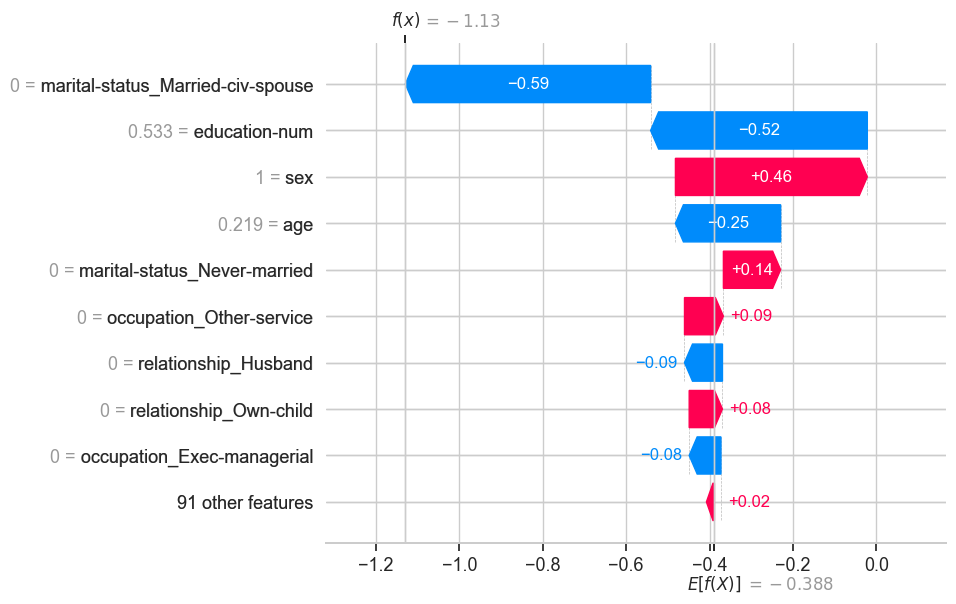

In [9]:
instance = 2
shap.plots.waterfall(
    shap.Explanation(
        values=explainer_artifacts["shap_values"][instance, :, 1],
        base_values=explainer_artifacts["expected_value"][1],
        data=X_probing.iloc[instance, :],
        feature_names=explainer_artifacts["feature_names"]
    )
)

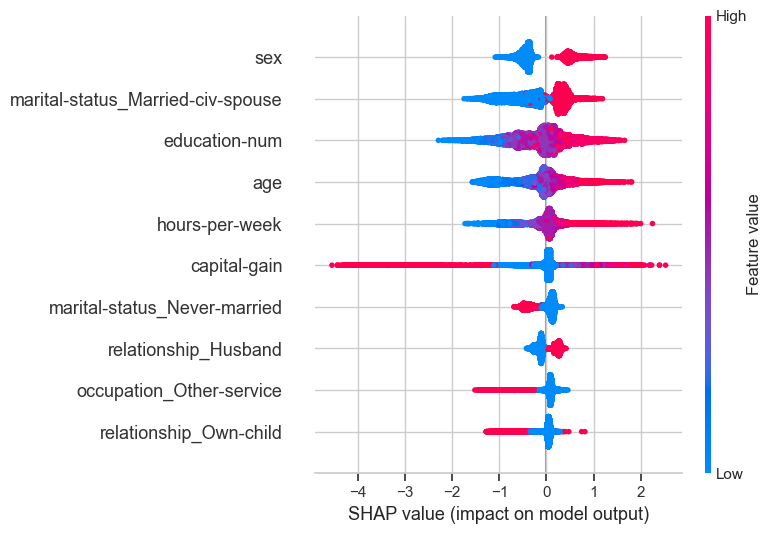

'# Change the colormap of the artists\nfor fc in plt.gcf().get_children():\n    for fcc in fc.get_children():\n        if hasattr(fcc, "set_cmap"):\n            fcc.set_cmap(cmap)\n            '

In [10]:
from matplotlib.colors import LinearSegmentedColormap

"""cmap = LinearSegmentedColormap.from_list(
    "blue_yellow",
    ["#FFD700", "#B9B48B", "#1E88E5"]
    # giallo → bianco → blu
)"""
import numpy as np
mask = X_probing[s] == 1  # tutte le femmine

mask = np.ones_like(X_probing[s], dtype=bool)

shap.summary_plot(
    explainer_artifacts["shap_values"][mask, :, 1],
    X_probing[mask],
    max_display=10
)

"""# Change the colormap of the artists
for fc in plt.gcf().get_children():
    for fcc in fc.get_children():
        if hasattr(fcc, "set_cmap"):
            fcc.set_cmap(cmap)
            """


In [11]:
# y_u -> predizioni mitigated (codificate)
# y_probing -> sarebbero le y normali (codificate)
# y_prime -> debiased/non debiased
# FAV: 1, UNFAV 0


df = results[0][(results[0]['sensitive']==s) & (results[0]['debiasing_lv']==lv) & (results[0]['debiasing_type']=="ThresholdOptimizer") & (results[0]['discr_model_type']=="XGBClassifier")]

# devo prendere chi è cambiato da y_probing da 0 a y_u a 1
y_probing = df['y_probing'].iloc[0]
y_u = df['y_u']

# tutte le femmine passate da outcome negativo a positivo
mask = (y_probing.iloc[0] == 0) & (y_u.iloc[0] == 1) & (X_probing[s]==1)
mask = X_probing[s]==1


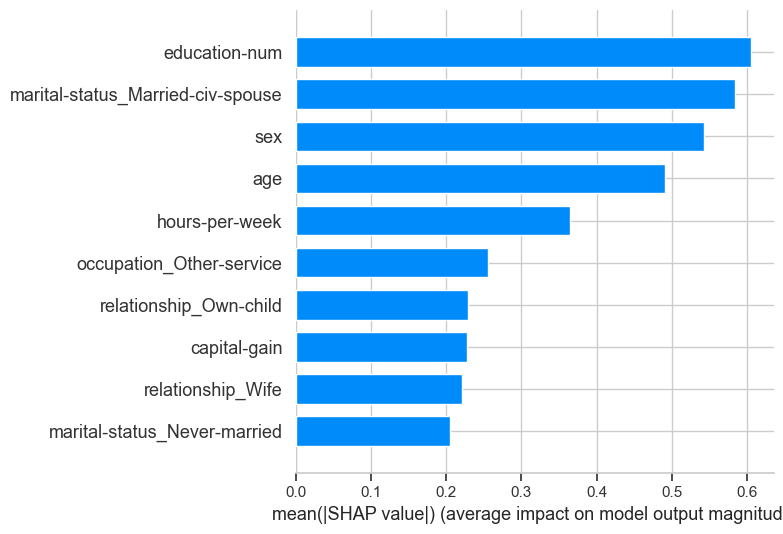

In [12]:

shap.summary_plot(
    explainer_artifacts["shap_values"][mask, :, 1],
    X_probing[mask],
    show=False,
    #color=cmap,
    max_display=10,
    plot_type="bar"
)


plt.show()

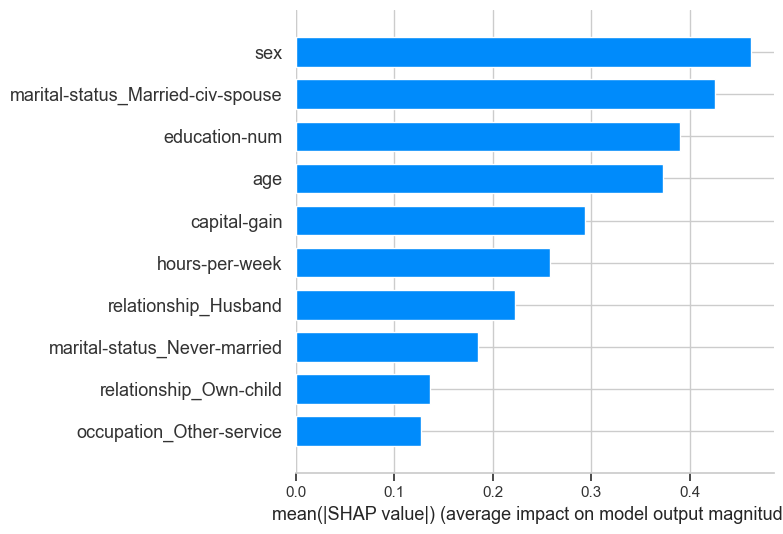

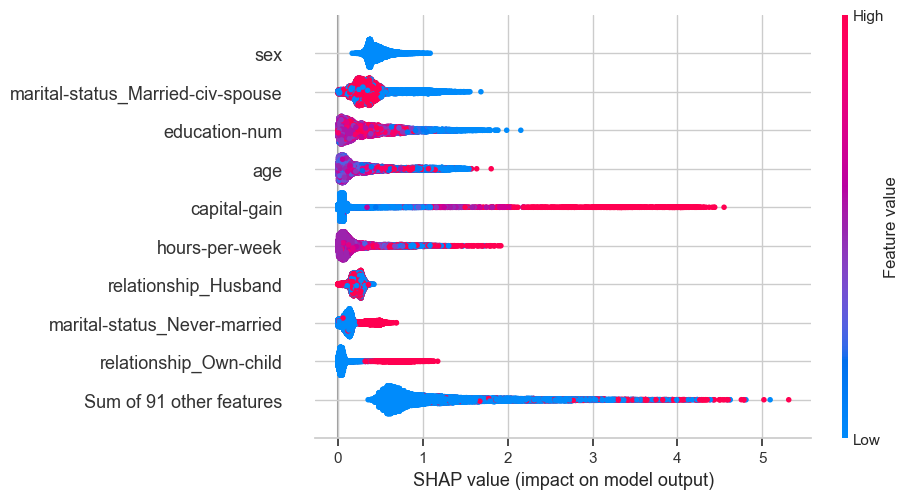

In [14]:
mask = X_probing[s]==0
# m
shap.summary_plot(
    explainer_artifacts["shap_values"][mask, :, 1],
    X_probing[mask],
    show=True,
    #color=cmap,
    max_display=10,
    plot_type="bar"
)


expl = shap.Explanation(
    values=np.abs(explainer_artifacts["shap_values"][mask, :, 1]),
    feature_names=X_probing.columns,
    data=X_probing[mask]
)

shap.plots.beeswarm(expl)

In [15]:
indices = mask[mask].index
indices[:100]

Index([  3,   4,   8,  10,  11,  12,  13,  14,  15,  16,  17,  18,  19,  20,
        22,  25,  26,  28,  31,  32,  34,  35,  37,  38,  40,  41,  42,  44,
        45,  46,  47,  48,  49,  50,  51,  52,  53,  55,  56,  59,  61,  62,
        63,  65,  66,  69,  70,  71,  72,  73,  74,  75,  77,  78,  79,  80,
        83,  84,  85,  86,  88,  89,  90,  93,  94,  95,  97,  98,  99, 100,
       104, 107, 111, 113, 114, 116, 117, 118, 120, 125, 126, 127, 128, 129,
       130, 131, 133, 134, 135, 136, 138, 139, 141, 146, 147, 148, 149, 151,
       152, 153],
      dtype='int64')

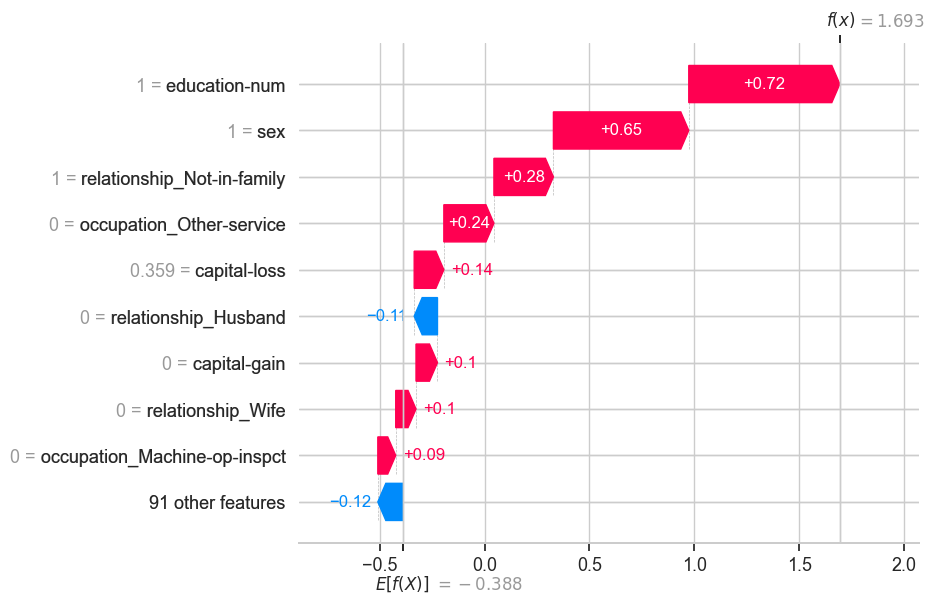

In [16]:
instance = 96
shap.plots.waterfall(
    shap.Explanation(
        values=explainer_artifacts["shap_values"][instance, :, 1],
        base_values=explainer_artifacts["expected_value"][1],
        data=X_probing.iloc[instance, :],
        feature_names=explainer_artifacts["feature_names"]
    ), show=False
)


# Change the colormap of the artists
for fc in plt.gcf().get_children():
    for fcc in fc.get_children():
        if hasattr(fcc, "set_cmap"):
            fcc.set_cmap(cmap)

plt.show()

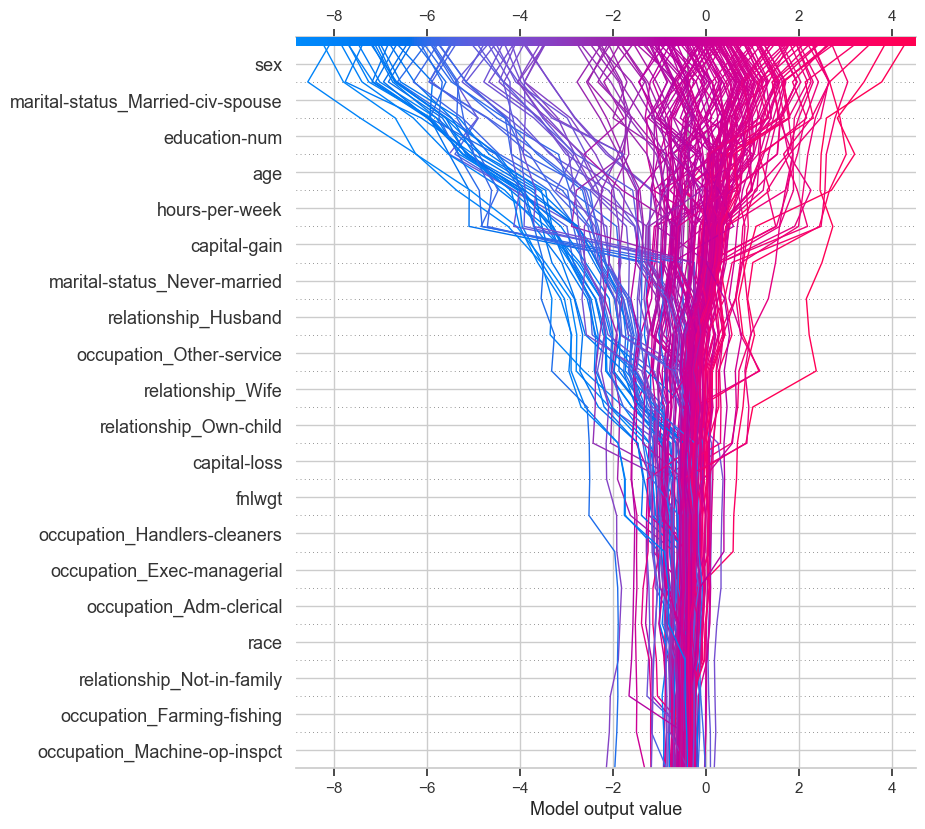

In [56]:
mask = np.ones_like(X_probing[s], dtype=bool)
idx = np.random.choice(np.where(mask)[0], size=200, replace=False)

shap.decision_plot(
    explainer_artifacts["expected_value"][1],
    explainer_artifacts["shap_values"][idx, :, 1],
    X_probing.iloc[idx],
    #plot_color=cmap
)

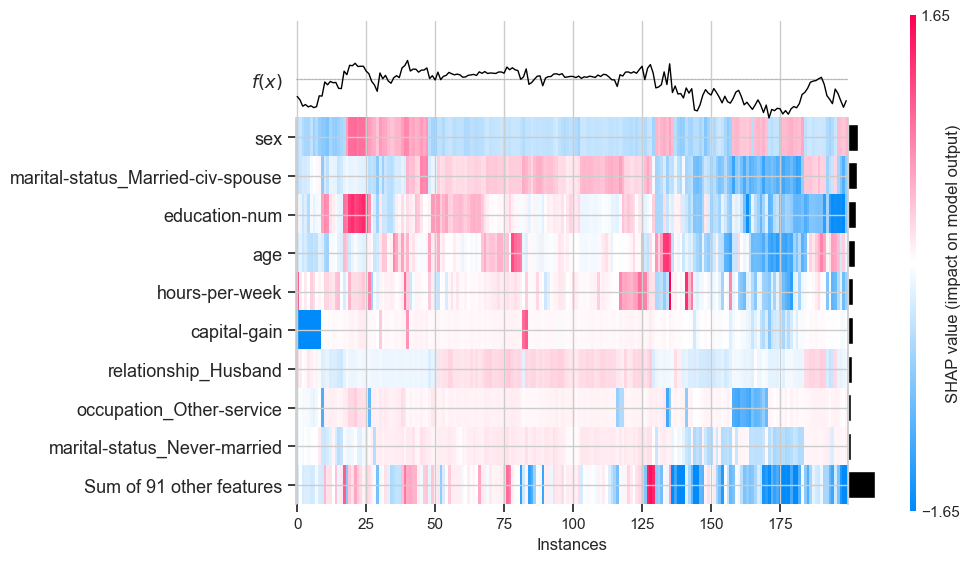

<Axes: xlabel='Instances'>

In [57]:
import shap
mask = np.ones_like(X_probing[s], dtype=bool)

idx = np.random.choice(np.where(mask)[0], size=200, replace=False)

shap_values = explainer_artifacts["shap_values"][idx, :, 1]

expl = shap.Explanation(
    values=shap_values,
    base_values=explainer_artifacts["expected_value"][1],
    data=X_probing.iloc[idx],
    feature_names=X_probing.columns
)

shap.plots.heatmap(expl)



In [ ]:
results[0][['discr_model_type', 'debiasing_type', 'debiasing_lv', 'discr_model_f1_score']]

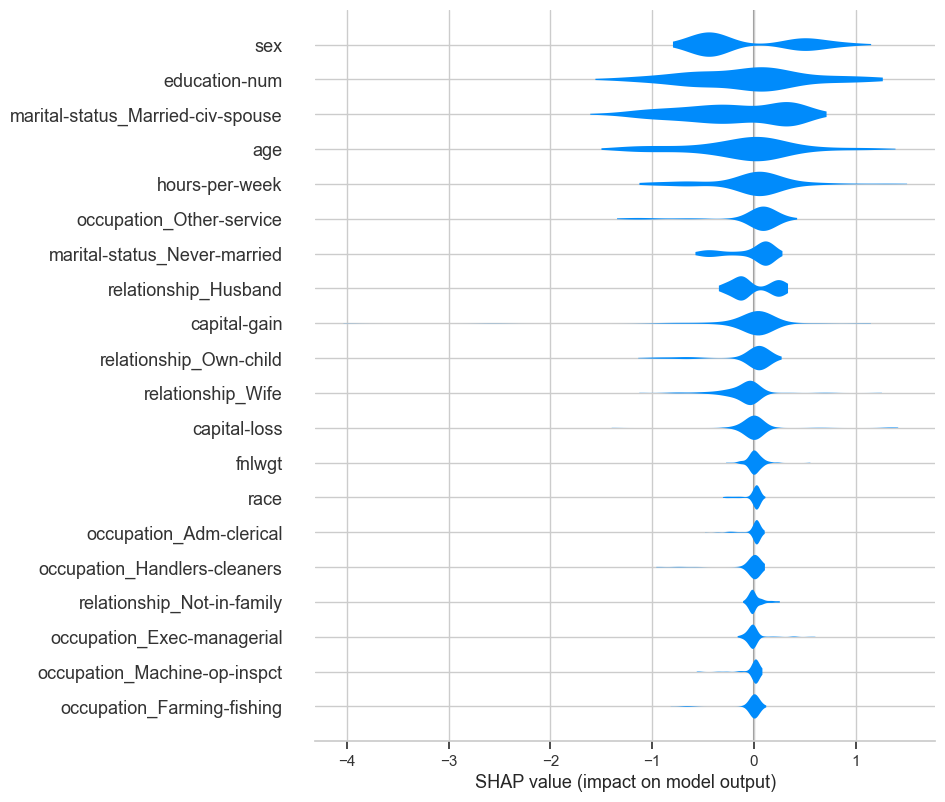

In [33]:
mask = np.ones_like(X_probing[s], dtype=bool)
idx = np.random.choice(np.where(mask)[0], size=200, replace=False)

shap.plots.violin(
    explainer_artifacts["shap_values"][idx, :, 1],
    feature_names=explainer_artifacts["feature_names"]
    #plot_color=cmap
)